# Source-file check: our samples, the 2025 productions, the 2024 cascade fix

This notebook reads the source files themselves: **ROOT where a ROOT conversion exists, `.wout`
otherwise**. It does not touch the HDF5 files, the energy-truth companion or any cached
extraction.

The paths in the table and on the figures are relative to `/eos/baikalgvd/` (so `mc/2020/...`
means `/eos/baikalgvd/mc/2020/...`); this keeps the in-panel labels readable.

| label | local files | EOS source | format | `fDate` |
|---|---|---|---|---|
| `nu2 v1.0` — our sample | `demo_root/eos/nue2_v1.0_bexmc_1000.root` | `mc/2020/prod1/nu2.100PeV/bexmc/10102/a/nu_mu_1000.root` | ROOT | 231018 |
| `nuatm v1.0` — our sample | `demo_root/eos/nuatm_v1.0_1000.wout` | `mc/2020/prod1/nuatm/wout/v1.0/10102/a/nu_mu_1000.wout` | wout | 220119 |
| `nu2 v3.0` — 2025 | `demo_root/eos/nu2_v3.0_1226..1273.wout` (48 files) | `mc/2020/nu2/wout/v3.0/10102/29/nu_mu_1226..1273.wout` | wout | 250506 |
| `nuatm v4.0` — 2025 | `demo_root/eos/nuatm_v4.0_1226..1267.wout` (42 files) | `mc/2020/nuatm/wout/v4.0/daemonc/10102/29/nu_mu_1226..1267.wout` | wout | 250515 |
| `nuatm 2024` — vertex-cascade fix | `demo_root/eos/nuatm2024_v3.0_1..10.wout` (10 files) | `mc/2024/nuatm/wout/v3.0/daemonc/10102/1/nu_mu_1..10.wout` | wout | 261022 |

The `v1.0` samples are the ones used throughout the project. `nue2_1000.root` matches
`mc/2020/prod1/nu2.100PeV/wout/v1.0/10102/a/nu_mu_1000.wout` event for event, and the EOS
`bexmc` ROOT has the same entries. For `nuatm` there is **no ROOT conversion on EOS**, so its
`wout` is read directly here; it is the source from which the ROOT used earlier was built.

**There is no ROOT conversion of the 2025 productions on EOS either.** A recursive listing of the
whole `mc/2020/nu2` and `mc/2020/nuatm` trees finds zero `.root` files; those trees contain only
`simgvd` (`.dat.gz`, `.log`, `.lst`, `.out.gz`) and `wout`. The newest ROOT files on EOS are the
v1.0 `bexmc` ones above. The 2024 set in this notebook is also `wout` only.

The 2025 examples are consecutive files of one batch, trigger `10102`, directory `29` — chosen so
that **each species has at least 3,000 events** in both selections used below (vertex inside a
cluster and sentinel single-track with cascades). The ROOT `fInteractions` array is read with
`TTree::Draw(..., "goff")` because `uproot` cannot read the `TClonesArray` leaves; the `.wout`
files are read with `data_manager/root2h5/mc_binary/read_wout.py`, which checks the record
length on every event.

**The 2024 set is a different detector configuration** — 4860 channels, 135 strings, 17 clusters
— unlike the 2020 samples (2016 channels, 56 strings, 7 clusters). It is the colleague's new
`nuatm` production where the hadronic shower at the interaction vertex is now recorded; 10 of
the 100 files are used here. The spectral comparison with the 2020 columns is therefore not
direct, but the vertex-cascade check is. The `closure` column in the table below checks
`Reg + E_cascade@vertex = E_nu` for events whose closest cascade is within 1 mm.

**How to run.** PyROOT is not in `baikal25`; ROOT 6.40.04 is installed in `rootcheck`:

```
conda run -n rootcheck jupyter nbconvert --to notebook --execute --inplace eos_production_check.ipynb
```

or open the notebook and pick the `rootcheck` kernel.


In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
import ROOT

ROOT.gErrorIgnoreLevel = ROOT.kFatal
HERE = Path.cwd()
sys.path.insert(0, str(HERE.parent / "root2h5" / "mc_binary"))
from read_wout import read_file as read_wout_file

C_LIGHT = 0.299792458
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e5e4e0", "#fcfcfb"
COLOR = {"nu2": "#2a78d6", "nuatm": "#eb6834", "nuatm2024": "#7a4fd6"}
SPECIES = [(+1, "ν", "#ff0000"), (-1, "ν̄", "#ff0000")]

FILES = {
    "nu2 v1.0 — our sample": dict(
        paths=[HERE / "demo_root/eos/nue2_v1.0_bexmc_1000.root"], kind="root", family="nu2"),
    "nuatm v1.0 — our sample": dict(
        paths=[HERE / "demo_root/eos/nuatm_v1.0_1000.wout"], kind="wout", family="nuatm"),
    "nu2 v3.0 — 2025": dict(
        paths=[HERE / f"demo_root/eos/nu2_v3.0_{i}.wout" for i in range(1226, 1274)],
        kind="wout", family="nu2"),
    "nuatm v4.0 — 2025": dict(
        paths=[HERE / f"demo_root/eos/nuatm_v4.0_{i}.wout" for i in range(1226, 1268)],
        kind="wout", family="nuatm"),
    "nuatm 2024 — vertex-cascade fix": dict(
        paths=[HERE / f"demo_root/eos/nuatm2024_v3.0_{i}.wout" for i in range(1, 11)],
        kind="wout", family="nuatm2024"),
}

EOS = {
    "nu2 v1.0 — our sample": dict(
        dir="mc/2020/prod1/nu2.100PeV/bexmc/10102/a/", files="nu_mu_1000.root"),
    "nuatm v1.0 — our sample": dict(
        dir="mc/2020/prod1/nuatm/wout/v1.0/10102/a/", files="nu_mu_1000.wout"),
    "nu2 v3.0 — 2025": dict(
        dir="mc/2020/nu2/wout/v3.0/10102/29/", files="nu_mu_1226..1273.wout"),
    "nuatm v4.0 — 2025": dict(
        dir="mc/2020/nuatm/wout/v4.0/daemonc/10102/29/", files="nu_mu_1226..1267.wout"),
    "nuatm 2024 — vertex-cascade fix": dict(
        dir="mc/2024/nuatm/wout/v3.0/daemonc/10102/1/", files="nu_mu_1..10.wout"),
}

def annotate_source(ax, label, loc="top"):
    e = EOS[label]
    text = f"EOS: {e['dir']}\n     {e['files']}"
    y, va = (0.985, "top") if loc == "top" else (0.015, "bottom")
    ax.text(0.012, y, text, transform=ax.transAxes, va=va, ha="left",
            fontsize=10, family="monospace", color=MUTED,
            bbox=dict(facecolor=SURFACE, edgecolor=GRID, linewidth=0.5, alpha=0.92, pad=1.5))

In [2]:
BRANCHES = {
    "e_nu":      "BMCEvent.fPrimaryParticleEnergy",
    "t_first":   "BMCEvent.fFirstMuonTime",
    "reg":       "BMCEvent.fSumEnergyBundleReg",
    "e_mu":      "BMCEvent.fTracks.fMuonEnergy",
    "n_tracks":  "BMCEvent.fResponseMuonsN",
    "theta":     "BMCEvent.fTracks.fTheta",
    "phi":       "BMCEvent.fTracks.fPhi",
    "ref_x":     "BMCEvent.fTracks.fX",
    "ref_y":     "BMCEvent.fTracks.fY",
    "ref_z":     "BMCEvent.fTracks.fZ",
    "n_casc":    "BMCEvent.fTracks.fInteractionN",
    "casc_e":    "BMCEvent.fTracks.fInteractions.fEnergy",
    "casc_x":    "BMCEvent.fTracks.fInteractions.fX",
    "casc_y":    "BMCEvent.fTracks.fInteractions.fY",
    "casc_z":    "BMCEvent.fTracks.fInteractions.fZ",
    "sign":      "BMCEvent.fNucleonN",
}

def draw(tree, expression, n_entries):
    n = tree.Draw(expression, "", "goff", n_entries, 0)
    if n < 0:
        raise RuntimeError(f"Draw failed: {expression}")
    return np.frombuffer(tree.GetV1(), dtype=np.float64, count=n).copy()

def read_root(path):
    tf = ROOT.TFile.Open(str(path))
    tree = tf.Get("Events")
    n = int(tree.GetEntries())
    tree.SetEstimate(max(n * 300, 1_000_000))
    out = {name: draw(tree, expr, n) for name, expr in BRANCHES.items()}
    tf.Close()
    out["n_entries"] = n
    return out

In [3]:
def read_wout(path):
    """Configuration + compact per-event arrays; full event dicts are not kept."""
    cfg, events = read_wout_file(path)
    first = []
    for e in events:
        if e["tracks"]:
            t = e["tracks"][0]
            first.append((t["e_muon"], np.asarray(t["position"], dtype=np.float64),
                          np.asarray(t["showers"], dtype=np.float64)))
        else:
            first.append((np.nan, np.zeros(3), np.empty((0, 4))))
    a = dict(
        e_nu=np.array([e["e_primary"] for e in events], dtype=np.float64),
        t_first=np.array([e["t_first_muon"] for e in events], dtype=np.float64),
        reg=np.array([e["e_bundle_reg"] for e in events], dtype=np.float64),
        n_tracks=np.array([e["n_tracks"] for e in events]),
        theta=np.array([e["theta"] for e in events], dtype=np.float64),
        phi=np.array([e["phi"] for e in events], dtype=np.float64),
        sign=np.array([e["a_primary"] for e in events], dtype=np.float64),
        ref_x=np.array([e["tracks"][0]["position"][0] if e["tracks"] else np.nan for e in events]),
        ref_y=np.array([e["tracks"][0]["position"][1] if e["tracks"] else np.nan for e in events]),
        ref_z=np.array([e["tracks"][0]["position"][2] if e["tracks"] else np.nan for e in events]),
        first_track=first,
    )
    a["n_entries"] = len(events)
    a["cfg"] = cfg
    return a

def read_wout_many(paths):
    parts = [read_wout(path) for path in paths]
    keys = ("e_nu", "t_first", "reg", "n_tracks", "theta", "phi", "sign",
            "ref_x", "ref_y", "ref_z")
    a = {k: np.concatenate([part[k] for part in parts]) for k in keys}
    a["first_track"] = [t for part in parts for t in part["first_track"]]
    a["n_entries"] = sum(part["n_entries"] for part in parts)
    a["cfg"] = parts[0]["cfg"]
    return a

In [4]:
def gaps_root(a):
    n_casc = a["n_casc"].astype(int)
    # the declared cascade count must equal the number of array elements actually returned
    assert n_casc.sum() == len(a["casc_e"]), "Draw returned a different number of cascades"
    starts = np.concatenate([[0], np.cumsum(n_casc)]).astype(int)

    selected = np.flatnonzero((np.isclose(a["e_mu"], -1e-3, atol=1e-9)) &
                              (a["n_tracks"] == 1) & (n_casc > 0))
    deltas, closest_e = [], []
    for i in selected:
        th, ph = np.radians(a["theta"][i]), np.radians(a["phi"][i])
        d = np.array([np.sin(th) * np.cos(ph), np.sin(th) * np.sin(ph), np.cos(th)])
        lo, hi = starts[i], starts[i] + n_casc[i]
        pts = np.stack([a["casc_x"][lo:hi], a["casc_y"][lo:hi], a["casc_z"][lo:hi]], axis=1)
        ref = np.array([a["ref_x"][i], a["ref_y"][i], a["ref_z"][i]])
        ds = (pts - ref) @ d - (-C_LIGHT * a["t_first"][i])
        deltas.append(ds)
        closest_e.append(float(a["casc_e"][lo + int(np.argmin(np.abs(ds)))]))
    return selected, deltas, closest_e

def gaps_wout(a):
    selected, deltas, closest_e = [], [], []
    for i, (e_mu, ref, showers) in enumerate(a["first_track"]):
        if a["n_tracks"][i] != 1:
            continue
        if abs(e_mu + 1e-3) > 1e-9:
            continue
        if not len(showers):
            continue
        selected.append(i)
        th, ph = np.radians(a["theta"][i]), np.radians(a["phi"][i])
        d = np.array([np.sin(th) * np.cos(ph), np.sin(th) * np.sin(ph), np.cos(th)])
        pts = showers[:, 1:4]
        ds = (pts - ref) @ d - (-C_LIGHT * a["t_first"][i])
        deltas.append(ds)
        closest_e.append(float(showers[int(np.argmin(np.abs(ds))), 0]))
    return np.asarray(selected), deltas, closest_e

In [5]:
data, vertex_e = {}, {}
for label, meta in FILES.items():
    if meta["kind"] == "root":
        a = read_root(meta["paths"][0])
        sel, deltas, closest_e = gaps_root(a)
    else:
        a = read_wout_many(meta["paths"])
        sel, deltas, closest_e = gaps_wout(a)
    sign_sel = a["sign"][sel]
    data[label] = (a, sel, deltas, sign_sel)
    vertex_e[label] = closest_e
    print(f"{label}: {a['n_entries']:,} events in {len(meta['paths'])} file(s), "
          f"{len(sel):,} sentinel single-track events with cascades, "
          f"{sum(len(x) for x in deltas):,} cascades "
          f"(ν {np.sum(sign_sel > 0):,}, ν̄ {np.sum(sign_sel < 0):,})")
    if meta["kind"] == "root":
        print(f"   declared cascade count vs elements read: "
              f"{a['n_casc'].sum():.0f} vs {len(a['casc_e'])}  -> "
              f"{'OK' if a['n_casc'].sum() == len(a['casc_e']) else 'MISMATCH'}")

nu2 v1.0 — our sample: 21,523 events in 1 file(s), 3,255 sentinel single-track events with cascades, 7,545 cascades (ν 3,255, ν̄ 0)
   declared cascade count vs elements read: 151712 vs 151712  -> OK


nuatm v1.0 — our sample: 39,547 events in 1 file(s), 5,050 sentinel single-track events with cascades, 7,099 cascades (ν 3,489, ν̄ 1,561)


nu2 v3.0 — 2025: 66,588 events in 48 file(s), 9,702 sentinel single-track events with cascades, 24,948 cascades (ν 6,507, ν̄ 3,195)


nuatm v4.0 — 2025: 88,169 events in 42 file(s), 10,002 sentinel single-track events with cascades, 13,894 cascades (ν 6,939, ν̄ 3,063)


nuatm 2024 — vertex-cascade fix: 10,931 events in 10 file(s), 4,149 sentinel single-track events with cascades, 5,477 cascades (ν 3,215, ν̄ 934)


In [6]:
print(f"{'file':26s} {'species':>7s} {'events':>7s} | " +
      " ".join(f"{'< ' + f'{t:.0e}':>8s}" for t in (1e-9, 1e-6, 1e-3, 1e-2, 1e-1)) +
      f" | {'closest, m':>12s} {'median, m':>10s} {'closure':>11s}")
for label, (a, sel, deltas, sign_sel) in data.items():
    for species, sp in ((+1, "ν"), (-1, "ν̄")):
        pairs = [(d, e, i) for d, e, i, s in zip(deltas, vertex_e[label], sel, sign_sel)
                 if s == species]
        if not pairs:
            print(f"{label:26s} {sp:>7s} {0:>7d} | {'—':>8s}" + " " * 46 +
                  f" | {'—':>11s}")
            continue
        closest = np.array([np.abs(d).min() for d, _, _ in pairs])
        c_ok = c_tot = 0
        for d, e, i in pairs:
            if np.abs(d).min() < 1.0:
                c = (a["reg"][i] + e * 1000.0) / a["e_nu"][i]
                c_tot += 1
                c_ok += abs(c - 1.0) < 1e-3
        closure = f"{c_ok}/{c_tot}" if c_tot else "—"
        row = " ".join(f"{100 * np.mean(closest < t):7.1f}%" for t in (1e-9, 1e-6, 1e-3, 1e-2, 1e-1))
        print(f"{label:26s} {sp:>7s} {len(pairs):>7,} | {row} | "
              f"{closest.min():>12.3g} {np.median(closest):>10.3g} {closure:>11s}")


file                       species  events |  < 1e-09  < 1e-06  < 1e-03  < 1e-02  < 1e-01 |   closest, m  median, m     closure
nu2 v1.0 — our sample            ν   3,255 |     0.0%     9.3%    97.0%    97.0%    97.0% |     7.45e-10   6.85e-06   3156/3156
nu2 v1.0 — our sample           ν̄       0 |        —                                               |           —
nuatm v1.0 — our sample          ν   3,489 |     0.0%     0.0%     0.0%     0.0%     0.1% |      0.00576       43.7        1/40
nuatm v1.0 — our sample         ν̄   1,561 |     0.0%     0.0%     0.0%     0.0%     0.0% |        0.129         42        0/18


nu2 v3.0 — 2025                  ν   6,507 |     0.0%     9.2%    96.8%    96.8%    96.8% |     3.96e-09   7.01e-06   6298/6299
nu2 v3.0 — 2025                 ν̄   3,195 |     0.0%     9.7%    96.2%    96.2%    96.2% |     1.13e-09   7.17e-06   3072/3072
nuatm v4.0 — 2025                ν   6,939 |     0.0%     0.0%     0.0%     0.0%     0.1% |       0.0281       43.3        0/61
nuatm v4.0 — 2025               ν̄   3,063 |     0.0%     0.0%     0.0%     0.0%     0.1% |         0.05       45.3        0/28
nuatm 2024 — vertex-cascade fix       ν   3,215 |     0.0%     4.2%    91.7%    91.7%    91.7% |     5.47e-10   1.41e-05   2947/2947
nuatm 2024 — vertex-cascade fix      ν̄     934 |     0.0%     4.7%    85.5%    85.5%    85.5% |     1.62e-08   1.52e-05     799/799


## The cascade at the vertex — ν and ν̄ on separate axes

Every point is one cascade, placed by `|Δs|`, its distance along the track from the muon's birth
point `s_v = −c·fFirstMuonTime`. Only sentinel single-track events with at least one cascade are
shown; the number of such events and their cascades is printed in each panel. The dashed line is
1 cm. Each panel carries its EOS source path (relative to `/eos/baikalgvd/`).

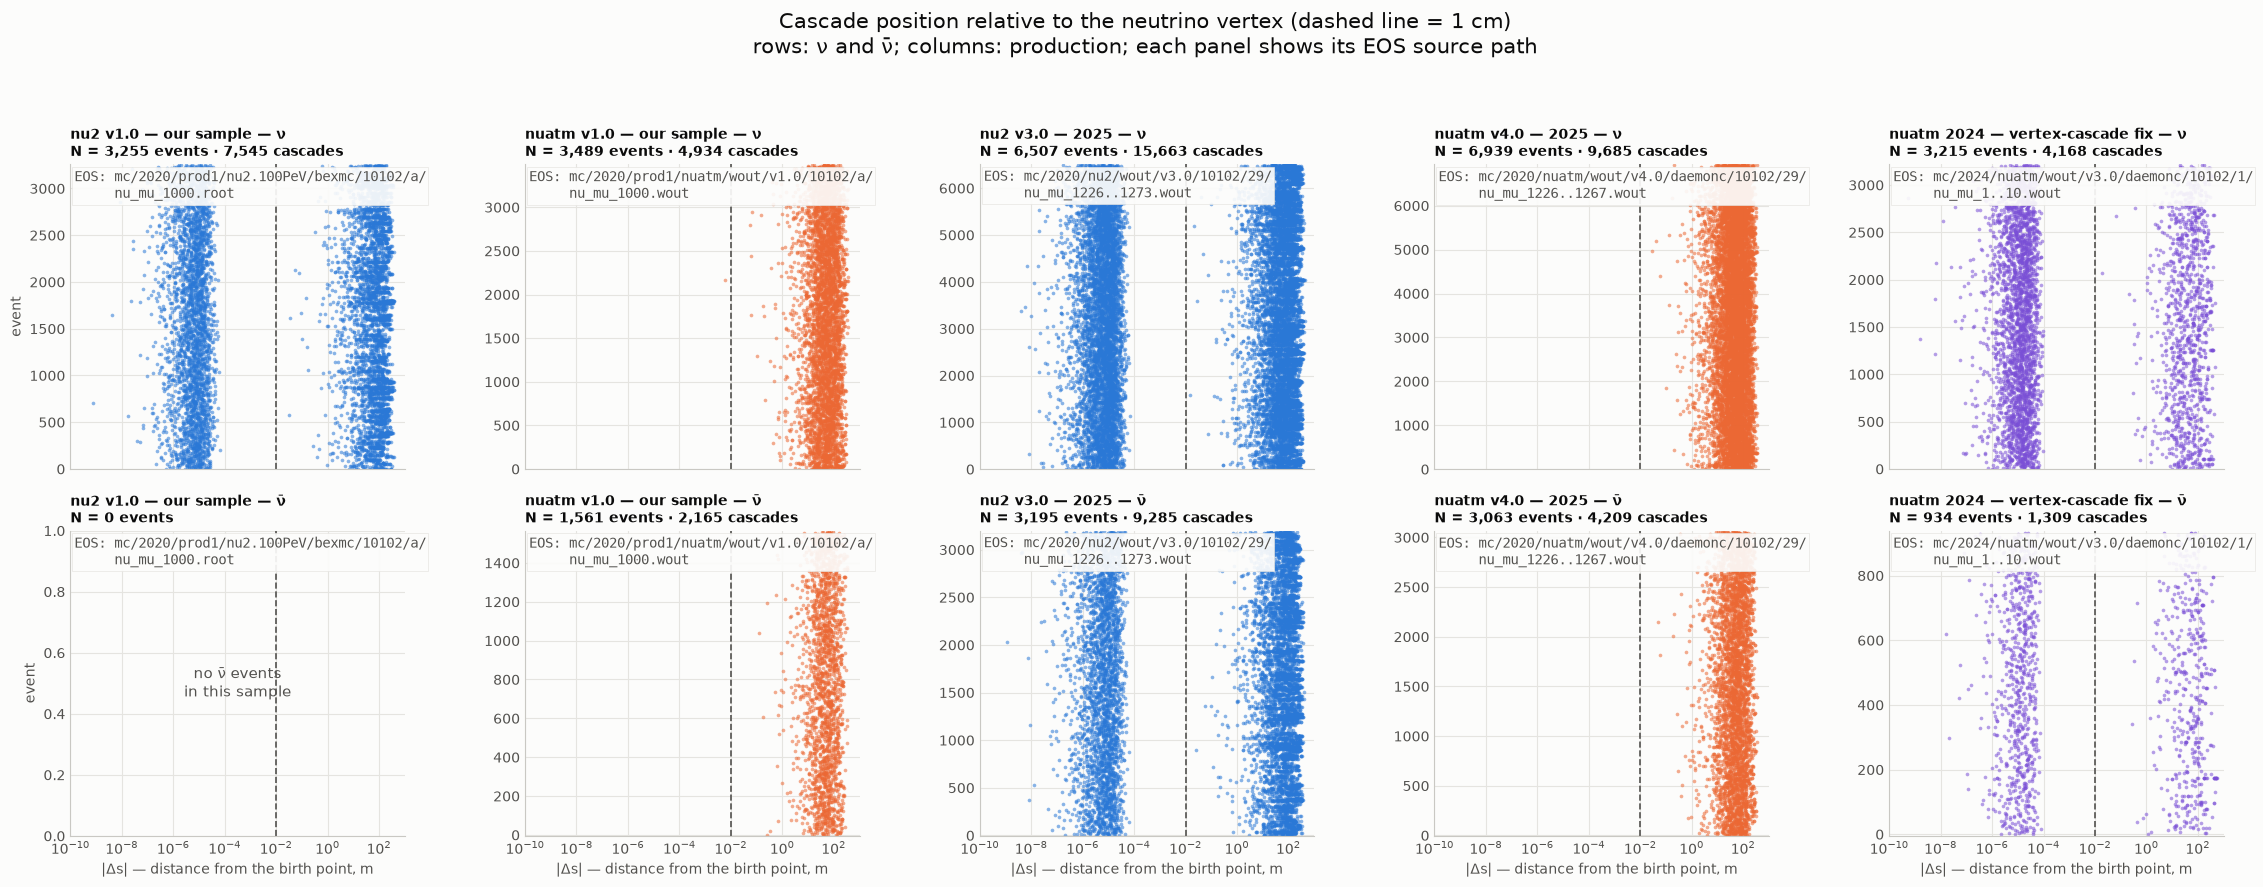

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(23, 9), sharex=True)
fig.patch.set_facecolor(SURFACE)

for row, (species, sp, color) in enumerate(SPECIES):
    for col, (label, (a, sel, deltas, sign_sel)) in enumerate(data.items()):
        ax = axes[row, col]
        ds = [d for d, s in zip(deltas, sign_sel) if s == species]
        ncasc = sum(len(x) for x in ds)
        ax.set_facecolor(SURFACE)
        ax.axvline(1e-2, color=MUTED, linestyle="--", linewidth=1.2)
        ax.set_xscale("log")
        ax.set_xlim(1e-10, 1e3)
        title = f"{label} — {sp}"
        if ds:
            title += f"\nN = {len(ds):,} events · {ncasc:,} cascades"
        else:
            title += "\nN = 0 events"
        ax.set_title(title, loc="left", fontsize=10, fontweight="bold", color=INK)
        annotate_source(ax, label)
        if ds:
            xs = np.concatenate([np.abs(x) for x in ds])
            ys = np.repeat(np.arange(len(ds)), [len(x) for x in ds])
            ax.scatter(xs, ys, s=7, color=COLOR[FILES[label]["family"]], alpha=0.55, linewidths=0)
            ax.set_ylim(-5, len(ds) + 5)
        else:
            ax.text(0.5, 0.5, f"no {sp} events\nin this sample", transform=ax.transAxes,
                    ha="center", va="center", color=MUTED, fontsize=11)
            ax.set_ylim(0, 1)
        if col == 0:
            ax.set_ylabel("event", color=MUTED)
        if row == 1:
            ax.set_xlabel("|Δs| — distance from the birth point, m", color=MUTED)
        ax.grid(color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color("#c9c8c3")
        ax.tick_params(colors=MUTED, length=0)

fig.suptitle("Cascade position relative to the neutrino vertex (dashed line = 1 cm)\n"
             "rows: ν and ν̄; columns: production; each panel shows its EOS source path",
             fontsize=15, color=INK)
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

## `y` versus `E_ν` — ν and ν̄ on separate axes

The vertex is `ref + s_v·d`; "inside a cluster" means inside the cylinder `r ≤ 60 m`,
`|z| ≤ 265 m` around any cluster centre. For the ROOT file the centres are computed from
`ArrayConfig`; for the `.wout` files from the channel table in the configuration record
(centimetres → metres). The two agree to 1e-5 m on the shared geometry.

`sign` is `BMCEvent.fNucleonN` for ROOT and `A_primary` in the event header for `.wout` — the
same field, `+1` for neutrinos and `−1` for antineutrinos (status `consistent`, see
`doc/claims_log.md`; not verified against NUGEN source). The number of events with the vertex
inside a cluster is printed in each panel.

In [8]:
def root_centres(path):
    tf = ROOT.TFile.Open(str(path))
    cfg = tf.Get("ArrayConfig")
    cfg.SetEstimate(1_000_000)
    def draw_cfg(expr):
        n = cfg.Draw(expr, "", "goff", 1, 0)
        return np.frombuffer(cfg.GetV1(), dtype=np.float64, count=n).copy()
    xyz = np.stack([draw_cfg(f"BGeomTel.fOMs.fPosition.f{c}") for c in "XYZ"], axis=1)
    tf.Close()
    return np.stack([xyz[i * 288:(i + 1) * 288].mean(axis=0) for i in range(len(xyz) // 288)])

def wout_centres(path):
    words = np.fromfile(path, dtype="<u4")
    cfg = words.view("<f4")[1:1 + int(words[0]) // 4]
    nch = int(cfg[4])
    ch = cfg[6:6 + 5 * nch].reshape(nch, 5)
    xyz = ch[:, :3].astype(np.float64) / 100.0          # cm -> m
    strings = ch[:, 4].astype(int)
    cluster_id = (strings - 1) // 8                      # 8 strings per cluster
    return np.stack([xyz[cluster_id == c].mean(axis=0)
                     for c in np.unique(cluster_id)])

def inside_any_cluster(a, centres, radius=60.0, z_half=265.0):
    th, ph = np.radians(a["theta"]), np.radians(a["phi"])
    d = np.stack([np.sin(th) * np.cos(ph), np.sin(th) * np.sin(ph), np.cos(th)], axis=1)
    vertex = np.stack([a["ref_x"], a["ref_y"], a["ref_z"]], axis=1) - C_LIGHT * a["t_first"][:, None] * d
    inside = np.zeros(len(vertex), dtype=bool)
    for centre in centres:
        rel = vertex - centre
        inside |= (np.hypot(rel[:, 0], rel[:, 1]) <= radius) & (np.abs(rel[:, 2]) <= z_half)
    return inside

for label, (a, sel, deltas, sign_sel) in list(data.items()):
    meta = FILES[label]
    centres = root_centres(meta["paths"][0]) if meta["kind"] == "root" else wout_centres(meta["paths"][0])
    inside = inside_any_cluster(a, centres)
    data[label] = (a, sel, deltas, sign_sel, inside)
    sign = a["sign"]
    print(f"{label}: {len(centres)} clusters; vertex inside {inside.sum():,} of {len(inside):,} "
          f"(ν {np.sum(inside & (sign > 0)):,}, ν̄ {np.sum(inside & (sign < 0)):,})")

nu2 v1.0 — our sample: 7 clusters; vertex inside 3,143 of 21,523 (ν 3,143, ν̄ 0)
nuatm v1.0 — our sample: 7 clusters; vertex inside 10,445 of 39,547 (ν 7,274, ν̄ 3,171)
nu2 v3.0 — 2025: 7 clusters; vertex inside 9,248 of 66,588 (ν 6,209, ν̄ 3,039)
nuatm v4.0 — 2025: 7 clusters; vertex inside 22,307 of 88,169 (ν 15,731, ν̄ 6,576)
nuatm 2024 — vertex-cascade fix: 17 clusters; vertex inside 3,288 of 10,931 (ν 2,560, ν̄ 728)


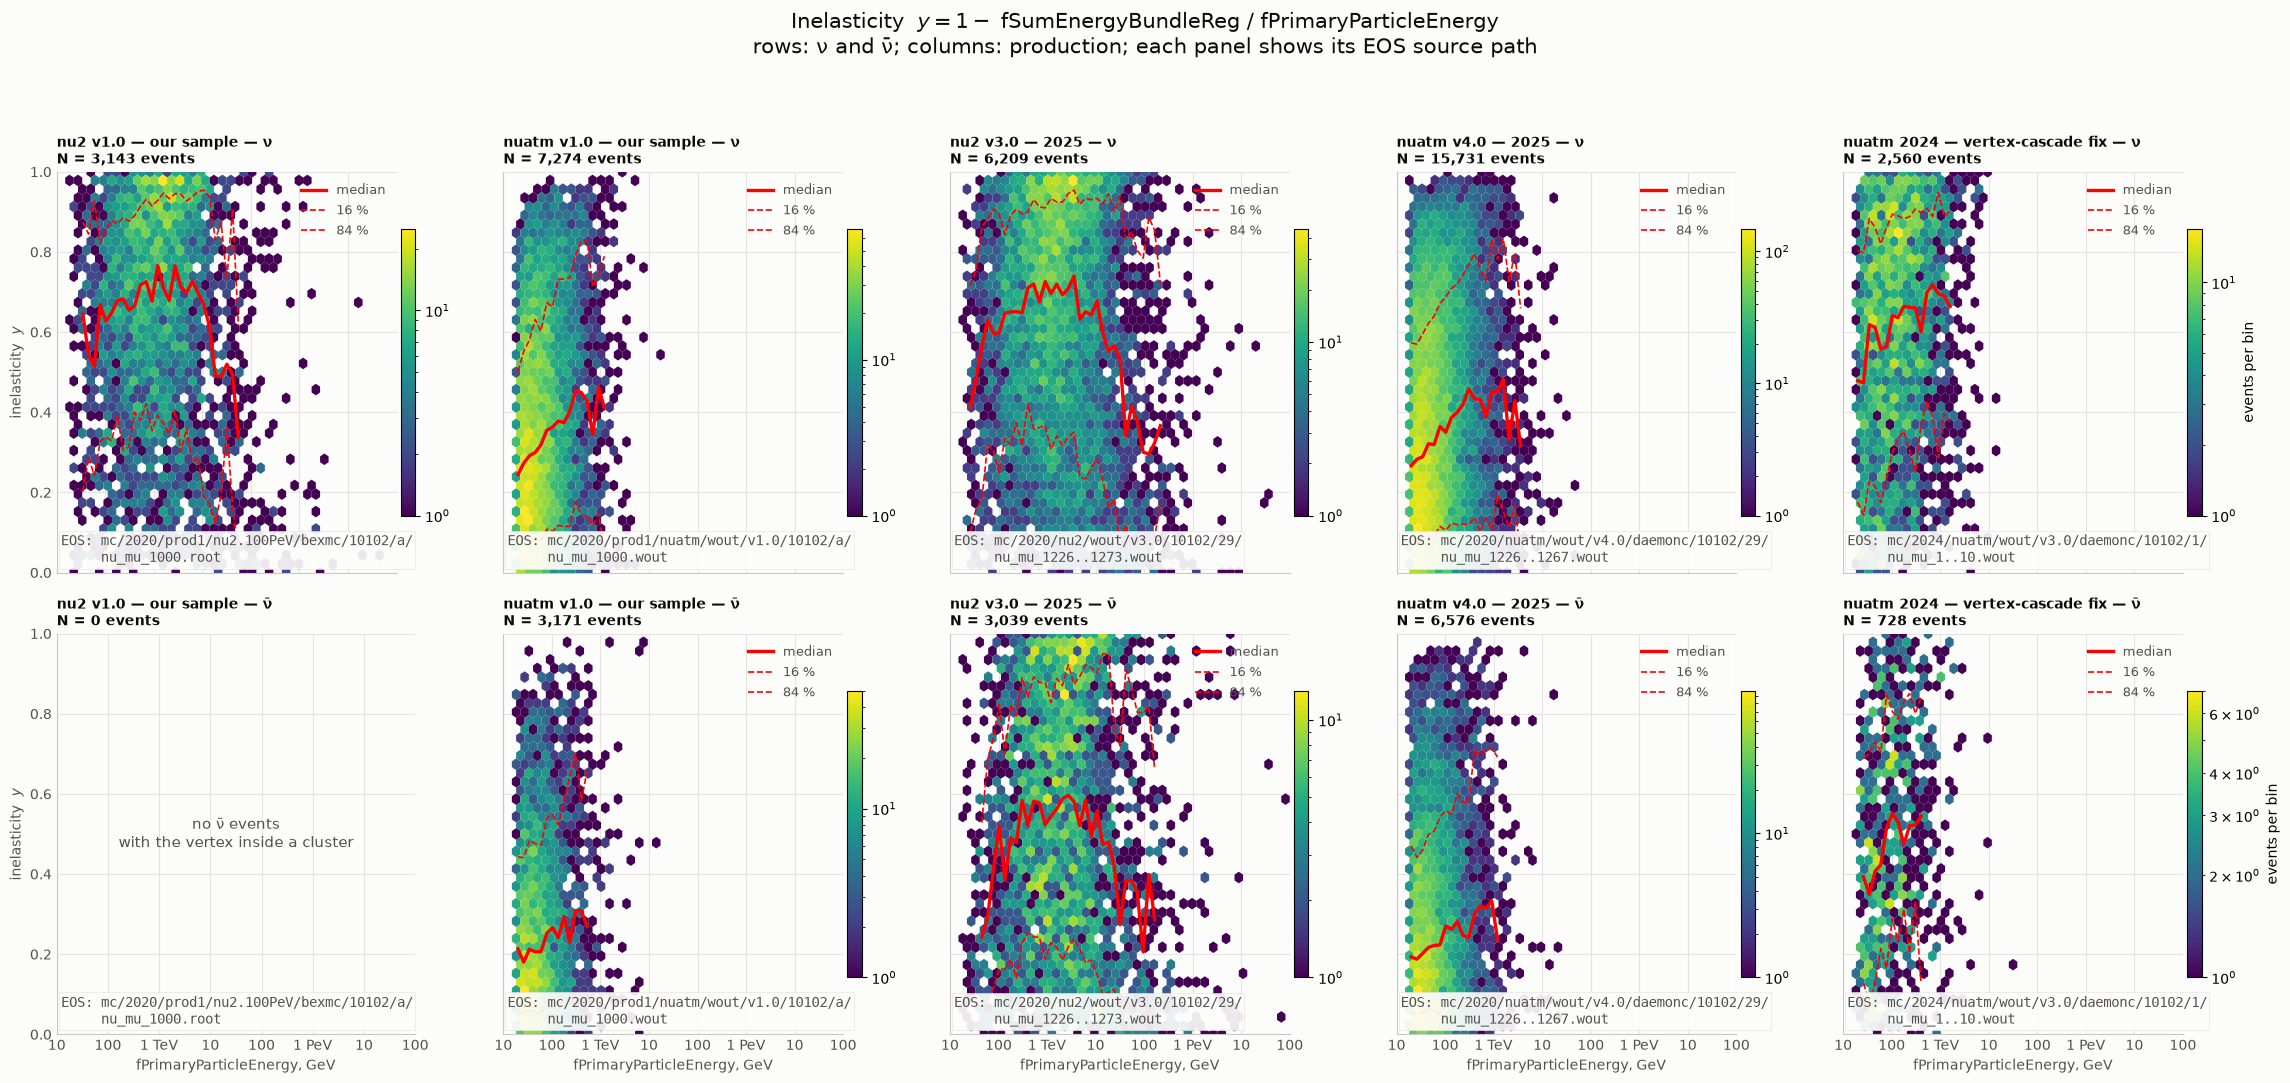

In [9]:
edges = np.logspace(1, 8, 60)
centres_of_bins = 0.5 * (edges[:-1] + edges[1:])

fig, axes = plt.subplots(2, 5, figsize=(23, 11), sharex=True, sharey=True)
fig.patch.set_facecolor(SURFACE)

for row, (species, sp, color) in enumerate(SPECIES):
    for col, (label, (a, sel, deltas, sign_sel, inside)) in enumerate(data.items()):
        ax = axes[row, col]
        m = inside & (a["sign"] == species)
        ax.set_facecolor(SURFACE)
        ax.set_xlim(1, 8); ax.set_ylim(0, 1)
        ax.set_title(f"{label} — {sp}\nN = {m.sum():,} events", loc="left",
                     fontsize=10, fontweight="bold", color=INK)
        annotate_source(ax, label, loc="bottom")
        if m.sum() >= 25:
            e_nu = a["e_nu"][m]
            y = (1 - a["reg"] / a["e_nu"])[m]
            hb = ax.hexbin(np.log10(e_nu), y, gridsize=40, extent=(1, 8, 0, 1), cmap="viridis",
                           bins="log", mincnt=1, linewidths=0)
            if col == len(data) - 1:
                fig.colorbar(hb, ax=ax, pad=0.012, fraction=0.040, label="events per bin")
            else:
                fig.colorbar(hb, ax=ax, pad=0.012, fraction=0.040)

            q = np.full((3, len(centres_of_bins)), np.nan)
            for k, (lo, hi) in enumerate(zip(edges[:-1], edges[1:])):
                mm = (e_nu >= lo) & (e_nu < hi)
                if mm.sum() >= 25:
                    q[:, k] = np.percentile(y[mm], [16, 50, 84])
            good = np.isfinite(q[1])
            xbins = np.log10(centres_of_bins[good])
            ax.plot(xbins, q[1][good], color=color, linewidth=2.4, label="median")
            ax.plot(xbins, q[0][good], color=color, linewidth=1.2, linestyle="--", label="16 %")
            ax.plot(xbins, q[2][good], color=color, linewidth=1.2, linestyle="--", label="84 %")
            ax.legend(frameon=False, labelcolor=MUTED, loc="upper right", fontsize=9)
        else:
            ax.text(0.5, 0.5, f"no {sp} events\nwith the vertex inside a cluster",
                    transform=ax.transAxes, ha="center", va="center", color=MUTED, fontsize=11)
        if col == 0:
            ax.set_ylabel("inelasticity  $y$", color=MUTED)
        if row == 1:
            ax.set_xticks(range(1, 9))
            ax.set_xticklabels(["10", "100", "1 TeV", "10", "100", "1 PeV", "10", "100"])
            ax.set_xlabel("fPrimaryParticleEnergy, GeV", color=MUTED)
        ax.grid(color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color("#c9c8c3")
        ax.tick_params(colors=MUTED, length=0)

fig.suptitle("Inelasticity  $y = 1 - $ fSumEnergyBundleReg $/$ fPrimaryParticleEnergy\n"
             "rows: ν and ν̄; columns: production; each panel shows its EOS source path",
             fontsize=15, color=INK)
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

## Reading the two halves

**Sample size.** The 2025 columns use 48 `nu2` and 42 `nuatm` files from batch 29; the 2024
column uses 10 of the 100 new `nuatm` files from `mc/2024/.../10102/1/`. The exact counts are
printed in the table and in the panel titles.

**The 2024 vertex-cascade fix.** The new 2024 `nuatm` files (4860 channels, 135 strings,
17 clusters, `fDate` 261022) record the hadronic shower at the interaction vertex. Unlike the
2020 `nuatm` columns, the 2024 ν and ν̄ panels show a dense line at `|Δs| ~ 1e-5 m`, and the
`closure` column — `Reg + E_cascade@vertex` against `E_nu` for events whose closest cascade is
within 1 mm — closes to 1e-3. This is the behaviour the colleague's fix was meant to produce;
the 2020 `nuatm` production has no vertex cascade, and the 2025 `nuatm` re-generation does not
add one.

**Cascade in the 2025 files.** The 2025 `nu2` has the cascade; the 2025 `nuatm` still does not.
The 2024 set is a separate, newer production; it is not a re-generation of the 2020 `nuatm`,
and its detector configuration differs (4860/135/17 against 2016/56/7). The y comparison with
the 2020 columns is therefore not direct; the vertex-cascade check is.

**Inelasticity.** The antineutrino median lies below the neutrino one in both `nuatm` files, as
expected for ν̄ DIS at low energy. For neutrinos only, the 2020 `nuatm` curve is still below the
`nu2` curve at low energy; the two approach each other as energy rises. The full-statistics HDF5
measurement gives a weighted mean `y` of 0.301 (nuatm ν) against 0.502 (nue2 ν) at 20–50 GeV,
0.511 against 0.571 at 1–3 TeV, and 0.557 against 0.576 at 10–30 TeV.

The earlier statement in `vertex_cascade_check.ipynb` — a factor 1.7–2 at **every** shared energy
— is true only at the low-energy end; above a few TeV the neutrino curves agree within ≈0.02–0.06.

Caveats, in the sense of `doc/claims_log.md`: the ±1 interpretation of `fNucleonN`/`A_primary`
is `consistent` (generator intensities, the ν̄/ν ratio, and the y ordering), not verified against
the NUGEN source. The 2024 column is 10 of 100 files and a different detector configuration, not
the full production; each other column is one production (one file for the v1.0 samples,
consecutive files of one batch for the 2025 samples).
